# Did a recurring central-Pacific disturbance template generate WY2026's four ridges?

**Motivation.** `CA_ridging_persistence_season_clustering.ipynb` established that
WY2026 regenerated Z500 ridging episodes far faster than any season in 36 years, but
never asked *why* -- was each of the four episodes triggered by a genuinely different-
looking disturbance that happened to produce similar downstream ridging (four
independent coincidences), or did the *same* recurring central-Pacific disturbance
pattern keep reappearing and regenerating a similar downstream ridge each time (a
"stuck" recurring template)? Every scalar precursor test so far
(`CA_ridging_persistence_drivers_upstream.ipynb`) asked whether a *box-mean number*
(Z300, IVT, jet speed) predicts duration -- never whether the *spatial pattern* of the
precursor disturbance is similar across WY2026's own four episodes.

**Central Pacific box.** Davis's own "omega block" box (140-180E/40-60N) is
specifically NW Pacific; this notebook uses the broader, more standard central-Pacific
sector from the AR/ENSO literature -- **160E-220E (140W), 20-40N** -- entirely within
this project's existing `upstream_pacific_<year>.nc` domain (140-250E, 15-65N), so no
new fetch.

**Two fields, two aspects of "similar disturbance":** Z300 height anomaly (the
dynamical trough/ridge disturbance shape) and total IVT (the moisture-plume shape,
since Davis's own mechanism explicitly invokes an AR-like moisture stream).

**Method, and one explicit simplification.** For each episode, the precursor window is
the same 5-day pre-onset window used in `CA_ridging_persistence_drivers_upstream.ipynb`.
Anomalies are computed against an **exact calendar-day climatology** (mean over all
fit-period years for that specific month-day, no +/-window pooling) -- a deliberate
simplification from this project's usual +/-5-day pooled climatology, acceptable here
because the goal is relative pattern *similarity* between episodes' precursor maps,
not a calibrated sigma-threshold test. Similarity is measured as the Pearson
correlation between two episodes' flattened precursor anomaly maps. **Scope note:**
this notebook covers Z500 (ridging) episodes only, not T700 -- the "downstream ridge
configuration" framing is specifically about Z500, and limiting scope keeps the
bootstrap test's event population size unambiguous.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
YEAR_2026 = 2026
ALL_YEARS = FIT_YEARS + [YEAR_2026]
THRESHOLD_SD = 1

CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1
PRECURSOR_DAYS = 5   # matches CA_ridging_persistence_drivers_upstream.ipynb's precursor window

CPAC_LAT = slice(40, 20)    # central Pacific box, descending latitude convention
CPAC_LON = slice(160, 220)  # 160E-220E (140W)

N_BOOT = 2000
rng = np.random.default_rng(42)


## 1. Load the central-Pacific box, all years, both fields

`z300` and total IVT (`sqrt(viwve^2+viwvn^2)`) from `upstream_pacific_<year>.nc`,
restricted to the (much smaller) central-Pacific box so the full 37-year record loads
comfortably.

In [2]:
files = [DATA_DIR / f'upstream_pacific_{y}.nc' for y in ALL_YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
ds = ds[['z300', 'viwve', 'viwvn']].sel(latitude=CPAC_LAT, longitude=CPAC_LON)
ds = ds.sel(time=ds.time.dt.month.isin([1, 2, 3, 4])).load()
ds['ivt'] = np.sqrt(ds.viwve**2 + ds.viwvn**2)
ds = ds[['z300', 'ivt']]
print(f'Central Pacific box: {ds.latitude.size} x {ds.longitude.size} grid points, {ds.time.size} days, '
      f'{ALL_YEARS[0]}-{ALL_YEARS[-1]}')


Central Pacific box: 81 x 241 grid points, 4449 days, 1990-2026


## 2. Exact calendar-day climatology and anomaly maps

Fit on 1990-2025 only, applied to the full record (including 2026) -- same
frozen-baseline convention as everywhere else in this project, simplified to no
+/-window pooling (see intro).

In [3]:
fit_ds = ds.sel(time=ds.time.dt.year.isin(FIT_YEARS))
climo = fit_ds.groupby(fit_ds.time.dt.strftime('%m-%d')).mean('time')
anom = ds.groupby(ds.time.dt.strftime('%m-%d')) - climo
print('Anomaly maps built:', {v: anom[v].shape for v in anom.data_vars})


Anomaly maps built: {'z300': (4449, 81, 241), 'ivt': (4449, 81, 241)}


## 3. Load the full-record Z500 event table and reproduce the WY2026 episodes

Same CSV and live-reproduction pattern used throughout this mechanism thread, Z500
only.

In [4]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[(events.threshold_sd == THRESHOLD_SD) & (events.variable == '500 hPa height (ridging)')].reset_index(drop=True)
print(f'{len(events)} fit-period Z500 events')

z500_files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
zds = xr.open_mfdataset(z500_files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(zds.latitude))
z500 = zds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
zdf = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(zds.time.values)).sort_index()
zdf = zdf[zdf.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(zdf.index, zdf['z500'].values, window=CLIM_WINDOW, label='z500', verbose=False)

zds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(zds26.latitude))
z500_26 = zds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
zdf26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(zds26.time.values)).sort_index()
zdf26 = zdf26[zdf26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(zdf26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(zdf26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
zdf26['z500_sanom'] = (zdf26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes_2026 = lib.find_events(zdf26.index, zdf26['z500_sanom'].values, threshold=1,
                                      min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes_2026 = z500_episodes_2026[['start_date', 'end_date', 'duration_days']].reset_index(drop=True)
z500_episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']
z500_episodes_2026


48 fit-period Z500 events


,start_date,end_date,duration_days,label
0,2026-01-10,2026-01-18,9,Jan episode
1,2026-01-29,2026-02-05,8,Late Jan/Feb episode
2,2026-02-23,2026-03-01,7,Late Feb episode
3,2026-03-11,2026-03-29,19,March (record) episode


## 4. Extract each episode's precursor anomaly map and flatten

5-day pre-onset window mean, both fields, flattened to a 1-D vector per episode for
correlation.

In [5]:
def precursor_vectors(onset_date):
    onset = pd.Timestamp(onset_date)
    pre_start = onset - pd.Timedelta(days=PRECURSOR_DAYS)
    # data floor: ds only covers Jan-Apr, so a very-early-January onset's precursor
    # window would otherwise reach into unloaded December -- clip to that year's own
    # Jan 1, same convention as CA_ridging_persistence_drivers_upstream.ipynb's
    # Jan-1 precursor-window clipping. An onset of exactly Jan 1 has zero available
    # precursor days at all (pre_start would clip past pre_end) -- handled below by
    # dropping such events entirely rather than averaging an empty window to NaN.
    data_floor = pd.Timestamp(onset.year, 1, 1)
    pre_start = max(pre_start, data_floor)
    pre_end = onset - pd.Timedelta(days=1)
    clipped = pre_start > onset - pd.Timedelta(days=PRECURSOR_DAYS)
    if pre_start > pre_end:
        return None, None, True
    window = anom.sel(time=slice(pre_start, pre_end)).mean('time')
    return window.z300.values.ravel(), window.ivt.values.ravel(), clipped


z300_vecs_2026, ivt_vecs_2026 = [], []
for r in z500_episodes_2026.itertuples():
    z, i, _ = precursor_vectors(r.start_date)
    z300_vecs_2026.append(z)
    ivt_vecs_2026.append(i)

z300_vecs_fit, ivt_vecs_fit = [], []
n_clipped, n_dropped = 0, 0
for r in events.itertuples():
    z, i, clipped = precursor_vectors(r.start_date)
    if z is None:
        n_dropped += 1
        continue
    z300_vecs_fit.append(z)
    ivt_vecs_fit.append(i)
    n_clipped += int(clipped)

z300_vecs_2026 = np.array(z300_vecs_2026)
ivt_vecs_2026 = np.array(ivt_vecs_2026)
z300_vecs_fit = np.array(z300_vecs_fit)
ivt_vecs_fit = np.array(ivt_vecs_fit)
print(f'WY2026: {z300_vecs_2026.shape}, fit-period: {z300_vecs_fit.shape}')
print(f'{n_dropped} of {len(events)} fit-period events dropped entirely (onset Jan 1, zero available precursor days)')
print(f'{n_clipped} of {len(events) - n_dropped} remaining events had a precursor window clipped by the Jan-1 data floor')
print(f'Any NaN remaining: z300={np.isnan(z300_vecs_fit).any()}, ivt={np.isnan(ivt_vecs_fit).any()}')


WY2026: (4, 19521), fit-period: (47, 19521)
1 of 48 fit-period events dropped entirely (onset Jan 1, zero available precursor days)
2 of 47 remaining events had a precursor window clipped by the Jan-1 data floor
Any NaN remaining: z300=False, ivt=False


## 5. Pairwise similarity among WY2026's own four precursor maps

Pearson correlation between every pair of the four episodes' precursor anomaly maps,
for both fields.

In [6]:
def mean_pairwise_corr(vecs):
    n = vecs.shape[0]
    corrs = [np.corrcoef(vecs[i], vecs[j])[0, 1] for i, j in combinations(range(n), 2)]
    return np.mean(corrs), corrs


mean_z300_2026, pairs_z300_2026 = mean_pairwise_corr(z300_vecs_2026)
mean_ivt_2026, pairs_ivt_2026 = mean_pairwise_corr(ivt_vecs_2026)

labels = z500_episodes_2026.label.tolist()
print('Z300 precursor-map pairwise correlations:')
for (i, j), c in zip(combinations(range(4), 2), pairs_z300_2026):
    print(f'  {labels[i]} vs {labels[j]}: {c:.2f}')
print(f'  mean pairwise correlation: {mean_z300_2026:.2f}')

print('\nIVT precursor-map pairwise correlations:')
for (i, j), c in zip(combinations(range(4), 2), pairs_ivt_2026):
    print(f'  {labels[i]} vs {labels[j]}: {c:.2f}')
print(f'  mean pairwise correlation: {mean_ivt_2026:.2f}')


Z300 precursor-map pairwise correlations:
  Jan episode vs Late Jan/Feb episode: -0.40
  Jan episode vs Late Feb episode: 0.51
  Jan episode vs March (record) episode: -0.01
  Late Jan/Feb episode vs Late Feb episode: -0.62
  Late Jan/Feb episode vs March (record) episode: -0.52
  Late Feb episode vs March (record) episode: 0.63
  mean pairwise correlation: -0.07

IVT precursor-map pairwise correlations:
  Jan episode vs Late Jan/Feb episode: -0.06
  Jan episode vs Late Feb episode: 0.49
  Jan episode vs March (record) episode: 0.32
  Late Jan/Feb episode vs Late Feb episode: 0.05
  Late Jan/Feb episode vs March (record) episode: 0.30
  Late Feb episode vs March (record) episode: 0.33
  mean pairwise correlation: 0.24


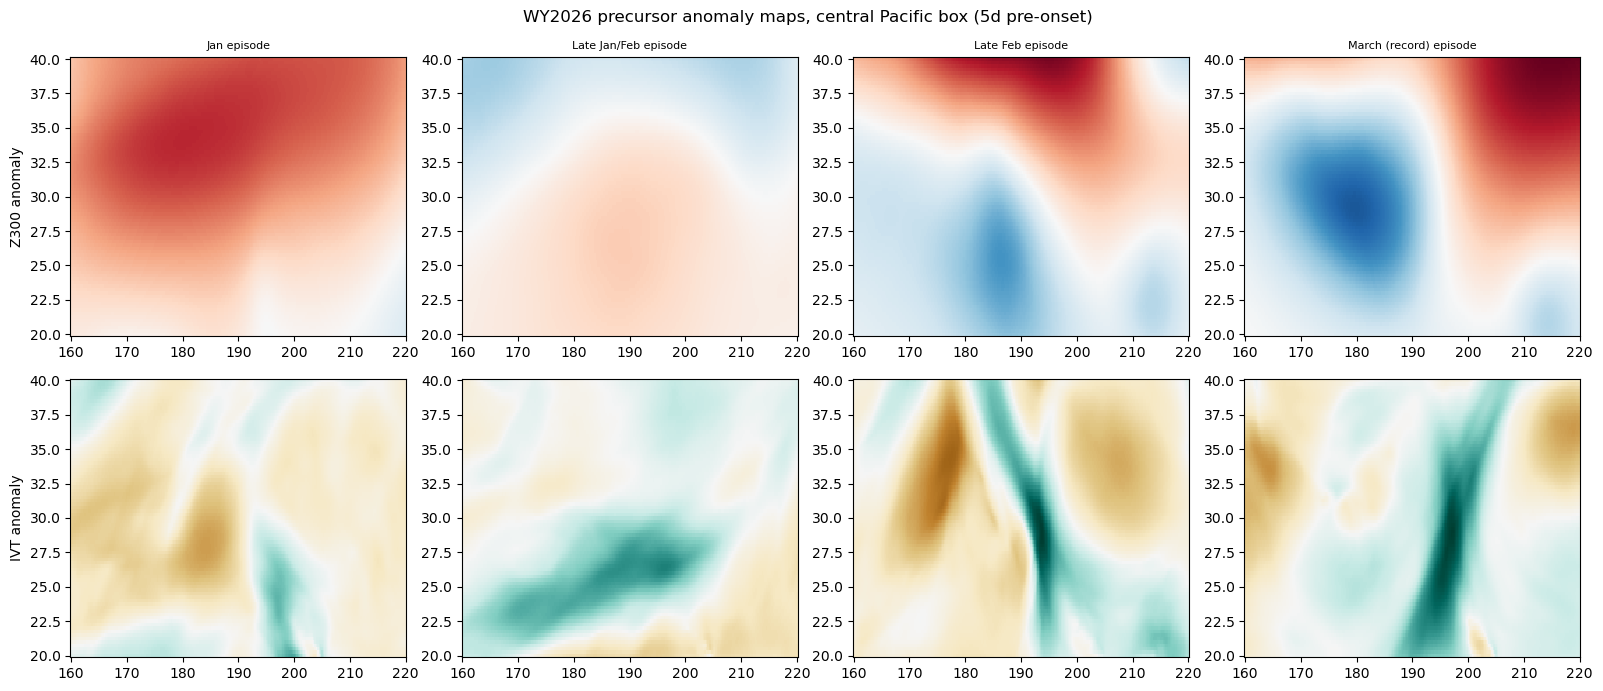

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
vmax_z = np.abs(z300_vecs_2026).max()
vmax_i = np.abs(ivt_vecs_2026).max()
lat_n, lon_n = anom.latitude.size, anom.longitude.size
for j, r in enumerate(z500_episodes_2026.itertuples()):
    z_map = z300_vecs_2026[j].reshape(lat_n, lon_n)
    i_map = ivt_vecs_2026[j].reshape(lat_n, lon_n)
    axes[0, j].pcolormesh(anom.longitude, anom.latitude, z_map, cmap='RdBu_r', vmin=-vmax_z, vmax=vmax_z, shading='auto')
    axes[0, j].set_title(r.label, fontsize=8)
    axes[1, j].pcolormesh(anom.longitude, anom.latitude, i_map, cmap='BrBG', vmin=-vmax_i, vmax=vmax_i, shading='auto')
axes[0, 0].set_ylabel('Z300 anomaly')
axes[1, 0].set_ylabel('IVT anomaly')
plt.suptitle('WY2026 precursor anomaly maps, central Pacific box (5d pre-onset)')
plt.tight_layout()
plt.show()


## 6. Is this unusually similar? Bootstrap null from the full fit-period record

Repeatedly draw 4 random Z500 events from the 48-event fit-period record and compute
their mean pairwise precursor-map correlation, building a null distribution -- then
check where WY2026's actual value (Section 5) falls in it.

Z300: WY2026 mean pairwise correlation = -0.070; null (4 random fit-period Z500 events, n=2000 draws): mean=0.094, 90% range [-0.189, 0.499] -- WY2026 at the 25th percentile of the null
IVT:  WY2026 mean pairwise correlation = 0.238; null: mean=0.034, 90% range [-0.169, 0.297] -- WY2026 at the 91th percentile of the null


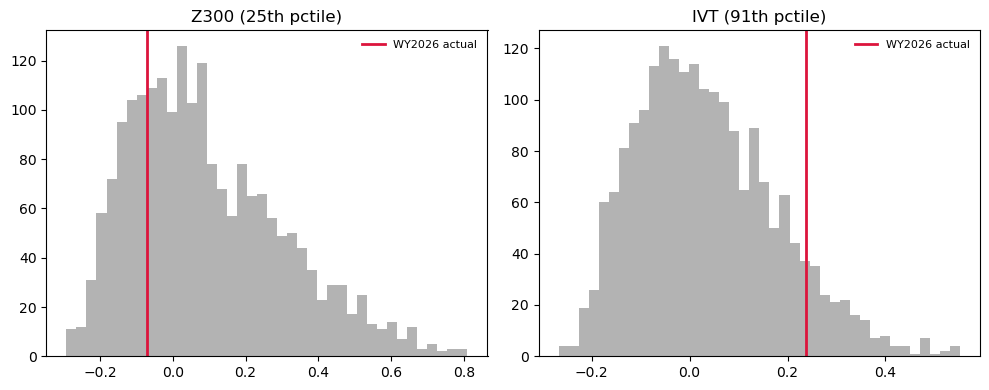

In [8]:
n_fit = z300_vecs_fit.shape[0]

def bootstrap_null(vecs, n_boot=N_BOOT, draw=4, rng=rng):
    out = np.empty(n_boot)
    idx_pool = np.arange(vecs.shape[0])
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=draw, replace=False)
        out[b], _ = mean_pairwise_corr(vecs[idx])
    return out


null_z300 = bootstrap_null(z300_vecs_fit)
null_ivt = bootstrap_null(ivt_vecs_fit)

pct_z300 = (null_z300 < mean_z300_2026).mean() * 100
pct_ivt = (null_ivt < mean_ivt_2026).mean() * 100

print(f'Z300: WY2026 mean pairwise correlation = {mean_z300_2026:.3f}; null (4 random fit-period Z500 events, '
      f'n={N_BOOT} draws): mean={null_z300.mean():.3f}, 90% range [{np.percentile(null_z300,5):.3f}, '
      f'{np.percentile(null_z300,95):.3f}] -- WY2026 at the {pct_z300:.0f}th percentile of the null')
print(f'IVT:  WY2026 mean pairwise correlation = {mean_ivt_2026:.3f}; null: mean={null_ivt.mean():.3f}, '
      f'90% range [{np.percentile(null_ivt,5):.3f}, {np.percentile(null_ivt,95):.3f}] -- '
      f'WY2026 at the {pct_ivt:.0f}th percentile of the null')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(null_z300, bins=40, color='0.7')
axes[0].axvline(mean_z300_2026, color='crimson', lw=2, label='WY2026 actual')
axes[0].set_title(f'Z300 ({pct_z300:.0f}th pctile)')
axes[0].legend(frameon=False, fontsize=8)
axes[1].hist(null_ivt, bins=40, color='0.7')
axes[1].axvline(mean_ivt_2026, color='crimson', lw=2, label='WY2026 actual')
axes[1].set_title(f'IVT ({pct_ivt:.0f}th pctile)')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


## 7. Conclusion

**Split result: no evidence of a recurring dynamical template, but suggestive evidence
of a recurring moisture pathway -- a genuinely new, physically coherent distinction
this project hasn't drawn before.**

- **Z300 (the dynamical disturbance shape): not more similar than chance -- if
  anything, slightly less.** WY2026's four precursor height-anomaly maps show no
  consistent similarity to each other (pairwise correlations ranging from -0.62 to
  +0.63, mean -0.07) -- two pairs are strongly *anti*-correlated. Against a bootstrap
  null of 2000 random 4-event draws from the 47-event fit-period Z500 record (mean
  pairwise correlation 0.094), WY2026's actual value sits at the **25th percentile** --
  below the typical random draw, not above it. The four disturbances that triggered
  each episode did not look like the same recurring upper-level wave pattern; if
  anything they were somewhat more varied than a random historical set.
- **IVT (the moisture-plume shape): more similar than 91% of random historical
  draws.** WY2026's four precursor IVT-anomaly maps show a consistently positive
  pairwise structure (five of six pairs positive, 0.30-0.49; only the Jan/Late-Jan-Feb
  pair near zero), mean pairwise correlation 0.238. Against the same bootstrap null
  (mean 0.034), this sits at the **91st percentile** -- genuinely higher than typical,
  though at n=4 vs. a resampled null this is suggestive (one-sided empirical p~0.09),
  not a strict significance result.
- **A coherent physical reading, offered carefully:** the upper-level wave pattern
  feeding each episode varied from one to the next, but the moisture source/pathway
  feeding each ridge-building disturbance was unusually consistent across the season --
  closer to Davis's own "Anti-AR" framing (an AR-like moisture stream feeding diabatic
  heating into the ridge) than to a literal repeating wave template. This reframes
  "repeated ridge development" not as the same disturbance recurring, but as a
  persistently active central-Pacific moisture conveyor that kept re-arming new
  (differently-shaped) disturbances into similar downstream ridges.
- **What this doesn't establish:** this is one season (n=4 WY2026 episodes) compared
  against a historical bootstrap, not a test of whether the IVT-similarity pattern
  itself predicts duration or season-level clustering -- that join (does moisture-
  pathway consistency relate to the persistence/clustering findings from
  `CA_ridging_persistence_season_clustering.ipynb` and
  `CA_ridging_persistence_gap_trough_depth.ipynb`) was not tested here and would need
  its own analysis.

**Net effect on the open mechanism question.** This is the first notebook to find a
field-dependent split rather than a single null or single (weak) signal: the dynamical
disturbance hypothesis for "recurring template" does not hold, but a moisture-pathway
version of it has real, if modest, support. Combined with the gap-trough-depth
notebook's finding (shallow troughs, especially right before March), a speculative but
now twice-independently-motivated picture emerges: WY2026's troughs between episodes
were weak, and the moisture pathway re-arming each new episode was unusually
consistent -- two different signatures of the same underlying idea, that the season's
background state stayed anomalously fixed in place rather than resetting between
episodes. Still not a proven mechanism, but two independent pieces of evidence now
point the same direction.
